In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

In [ ]:
import os

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,3,4,5,6")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc
import re
import random
import logging
from collections import Counter

import torch
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.models import ModelandTokenizer
from src.tokens import prepare_input
from src.goals.functional import apply_chat_template
from src.goals.condition_data import INT_PREDICATES, ConditionSpec, ConditionSample
from src.utils import logging_utils
import transformers

logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)


def rich_print(*a, **k):
    console.print(*a, **k)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")


# MODEL_NAME = "Qwen/Qwen2.5-Coder-14B-Instruct"
# MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_NAME = "Qwen/Qwen2.5-72B-Instruct"

2026-06-19 13:23:17 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-06-19 13:23:17 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=6, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-06-19 13:23:17 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from transformers import BitsAndBytesConfig

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
    # quantization_config = BitsAndBytesConfig(
    #     load_in_8bit=True
    # )
)
print(f"n_layer={mt.n_layer}, n_heads={mt.model.config.num_attention_heads}")

2026-06-18 23:38:24 src.models WARNING  Qwen/Qwen2.5-72B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


2026-06-18 23:38:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-72B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-18 23:38:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-72B-Instruct/495f39366efef23836d0cfae4fbe635880d2be31/config.json "HTTP/1.1 200 OK"
2026-06-18 23:38:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-72B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-18 23:38:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-72B-Instruct/495f39366efef23836d0cfae4fbe635880d2be31/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-18 23:38:25 httpx INFO     HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-72B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-06-18 23:38:25 httpx INFO     HTTP Request: GET ht

Loading weights:   0%|          | 0/963 [00:00<?, ?it/s]

2026-06-18 23:39:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-72B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-18 23:39:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-72B-Instruct/495f39366efef23836d0cfae4fbe635880d2be31/generation_config.json "HTTP/1.1 200 OK"
2026-06-18 23:39:09 src.models INFO     loaded model <Qwen/Qwen2.5-72B-Instruct> | size: 138676.079 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=80, n_heads=64


# 04.2 · Forced-prefill — does the LM stay on the current variable or move on?

**Setup.** Pick a *target slot* `k` ∈ {`b`,`c`,`d`}. Every **prior** condition (slots `< k`) is force-filled **complete**, as a random mix of single/multi-line impls but with **≥1 multiline** — so the LM has in-context precedent that a variable *may* span multiple lines. The **target** condition is the test variable, forced one of two ways:

- **multiline** — only the *first* (INCOMPLETE) line of a multi-line impl (e.g. `b = int(abs(n) ** 0.5)`). *Hypothesis:* the LM **stays on `b`** to finish it → `continue`.
- **singleline** — one COMPLETE line that fully checks the condition (e.g. `b = n % 2 == 0`). *Hypothesis:* the LM **moves on** to the next var → `moved_on`.

We score `hypothesis_ok = (verdict == expected_verdict)`. Verdict comes from the first assignment statement in the continuation (skips `for`/`if`): `continue` (target var) / `moved_on` (next var) / `other`. `PROMPT_MODE` selects chat vs FIM delivery.

We confirm on `b` first, then `c` and `d` (the per-slot rows in the summary).

In [4]:
from typing import Callable

# ── prompt preparation ──
MULTILINE_PREDS = [p for p in INT_PREDICATES if p.is_multiline]
VAR_LETTERS = "abcdefghij"
FIM_PREFIX, FIM_SUFFIX, FIM_MIDDLE = "<|fim_prefix|>", "<|fim_suffix|>", "<|fim_middle|>"
print(f"{len(MULTILINE_PREDS)} multiline predicates:", [p.id for p in MULTILINE_PREDS])


def result_print(letters):
    """Fixed FIM suffix: an f-string print that references EVERY result var (so to make the
    suffix valid the model must define each one in the middle)."""
    conds = ", ".join("Condition %d: {%s}" % (i + 1, v) for i, v in enumerate(letters))
    all_expr = " and ".join(letters)
    return '    print(f"' + conds + ", ALL: {" + all_expr + '}")\n'

def replace_in_code_newline_with_tabnewline(prompt: str):
    code_split = prompt.split("<code>")
    code_segment = code_split[-1]
    prefix = "<code>".join(code_split[:-1])
    code_segment = code_segment.replace("\n", "    \n")
    return prefix + "<code>" + code_segment

def build_example(rng, target_slot, n_conditions, mode="chat", style="multiline", aug: Callable | None = None):
    """Forced-prefill example for the 'stay vs move-on' test.

    PRIOR conditions (slots < target) are ALWAYS force-filled COMPLETE, as a random single/multi
    mix but with >=1 multiline — so the LM has in-context precedent that a variable MAY span
    multiple lines.  The TARGET condition (slot `target_slot`) is the test variable:
      - style="multiline":  forced at its first (INCOMPLETE) line -> hypothesis 'continue' (stay).
      - style="singleline": forced as one COMPLETE line           -> hypothesis 'moved_on'.
    Requires target_slot >= 1 (need >=1 prior to set the multiline precedent) and a following
    condition (for 'moved_on' to be possible).
    """
    assert 1 <= target_slot < n_conditions
    preds = [rng.choice(MULTILINE_PREDS) for _ in range(n_conditions)]
    params = [p.sample_params(rng) for p in preds]
    spec = ConditionSpec(
        spec_id=f"ml_s{target_slot}_{style[:3]}_{rng.randrange(10 ** 6):06d}",
        predicate_ids=[p.id for p in preds],
        predicate_params=params,
        spec_texts=[p.render(pr) for p, pr in zip(preds, params)],
        id_substrs=[p.render_substrs(pr) for p, pr in zip(preds, params)],
        test_inputs=[rng.randint(-5, 1000) for _ in range(6)],
    )
    sample = ConditionSample(spec=spec, lang="python", modularity="monolithic",
                             without_comment=True)
    stub = sample.render_code_stub()

    # priors: force-filled COMPLETE, random single/multi mix, but >=1 multiline
    prior_styles = [rng.choice(["multiline", "singleline"]) for _ in range(target_slot)]
    if "multiline" not in prior_styles:
        prior_styles[rng.randrange(target_slot)] = "multiline"
    body = []
    for j in range(target_slot):
        if prior_styles[j] == "multiline":
            body += preds[j].render_multiline(params[j], VAR_LETTERS[j])
        else:
            body.append(preds[j].render_singleline(params[j], VAR_LETTERS[j]))

    # target: the test variable
    if style == "multiline":
        target_impl = preds[target_slot].render_multiline(params[target_slot], VAR_LETTERS[target_slot])
        target_first = target_impl[0]                 # incomplete first line
        expected_rest = "\n".join(target_impl[1:])
        expected_verdict = "continue"
    else:
        target_first = preds[target_slot].render_singleline(params[target_slot], VAR_LETTERS[target_slot])
        expected_rest = ""                            # complete; nothing left for this var
        expected_verdict = "moved_on"
    body.append(target_first)

    letters = [VAR_LETTERS[i] for i in range(n_conditions)]
    fim_suffix = result_print(letters)
    if mode == "fim":
        doc = ('    """\n'
               + "".join(f"    {i + 1}. {t}\n" for i, t in enumerate(spec.spec_texts))
               + '    """\n')
        prefix_code = stub + doc + "\n".join(body) + "\n"
        full_prompt = FIM_PREFIX + prefix_code + FIM_SUFFIX + fim_suffix + FIM_MIDDLE
    else:
        prefix_code = stub + "\n".join(body) + "\n"
        full_prompt = apply_chat_template(
            mt=mt, user_query=sample.render_instruction().strip(), incomplete_code=prefix_code
        )

    full_prompt = aug(full_prompt) if aug else full_prompt
    next_slot = target_slot + 1
    return {
        "spec_id": spec.spec_id,
        "mode": mode,
        "prefill_style": style,             # the TARGET's style (test variable)
        "prior_styles": prior_styles,       # complete priors, >=1 multiline
        "full_prompt": full_prompt,
        "prefill_code": prefix_code,
        "fim_suffix": fim_suffix.rstrip("\n") if mode == "fim" else None,
        "target_slot": target_slot,
        "target_var": VAR_LETTERS[target_slot],
        "next_var": VAR_LETTERS[next_slot] if next_slot < n_conditions else None,
        "target_pred": preds[target_slot].id,
        "target_first_line": target_first.strip(),
        "expected_rest": expected_rest,
        "expected_verdict": expected_verdict,
        "n_conditions": n_conditions,
    }

19 multiline predicates: ['even', 'odd', 'divisible', 'perfect_square', 'perfect_cube', 'triangular', 'palindrome', 'reversed_greater', 'num_digits_ge', 'set_bits_gt', 'power_of_two', 'coprime_with', 'digit_sum_gt', 'digit_sum_divisible', 'digit_product_gt', 'all_digits_even', 'num_divisors_gt', 'abundant', 'prime']


In [8]:
# ── build the example set: target slot (b/c/d) x target prefill style ──
SEED = 0
N_PER_CELL = 10            # per (slot, style)
SLOTS = [1, 2, 3]          # b, c, d  (target; priors are slots < k, force-filled complete)
STYLES = ["multiline", "singleline"]
PROMPT_MODE = "chat"        # "chat" | "fim"

rng = random.Random(SEED)
examples = [
    build_example(rng, target_slot=k, n_conditions=k + 2, mode=PROMPT_MODE, style=st)
    for k in SLOTS
    for st in STYLES
    for _ in range(N_PER_CELL)
]
print(f"[{PROMPT_MODE}] {len(examples)} examples"
      f"  | style: {dict(Counter(e['prefill_style'] for e in examples))}"
      f"  | target: {dict(Counter(e['target_var'] for e in examples))}")

[chat] 60 examples  | style: {'multiline': 30, 'singleline': 30}  | target: {'b': 20, 'c': 20, 'd': 20}


In [9]:
# ── sanity vis: a multiline (incomplete) and a singleline (complete) prefill, slot 'b' ──
out = []
for st in STYLES:
    EX = [e for e in examples if e["prefill_style"] == st and e["target_slot"] == 1][0]
    if not EX:
        continue
    forced = EX["target_first_line"]
    out += [
        f"[bold]══ {st} ══[/bold]  spec={EX['spec_id']}  mode={EX['mode']}  "
        f"target_var=[cyan]{EX['target_var']}[/cyan]  next_var={EX['next_var']}  "
        f"pred=[magenta]{EX['target_pred']}[/magenta]  expect=[bold]{EX['expected_verdict']}[/bold]",
        f"forced last line: [yellow]{escape(repr(forced))}[/yellow]",
    ]
    for ln in EX["prefill_code"].rstrip("\n").split("\n"):
        if ln.strip() == forced:
            tag = "forced (incomplete)" if st == "multiline" else "forced (complete)"
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]   <- {tag}")
        else:
            out.append(escape(ln))
    out.append("")
rich_print("\n".join(out))

══ multiline ══  spec=ml_s1_mul_424604  mode=chat  target_var=b  next_var=c  pred=digit_sum_divisible  
expect=continue
forced last line: 'b = sum(int(d) for d in str(abs(n)))'
def check_conditions(n: int):
    a = sum(int(d) for d in str(abs(n)))
    a = a > 15
    b = sum(int(d) for d in str(abs(n)))   <- forced (incomplete)

══ singleline ══  spec=ml_s1_sin_615592  mode=chat  target_var=b  next_var=c  pred=perfect_square  expect=moved_on
forced last line: 'b = n >= 0 and int(abs(n) ** 0.5) ** 2 == n'
def check_conditions(n: int):
    a = bin(n).count("1")
    a = n > 0 and a == 1
    b = n >= 0 and int(abs(n) ** 0.5) ** 2 == n   <- forced (complete)

In [10]:
e = EX
print(e["full_prompt"])

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is a power of two
2. n is a perfect square
3. all of n's digits are even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any helper functions.
Do not include any co

## Generate

Greedy, short horizon — we only need the first couple of continuation lines.

In [11]:
# ── batched greedy generation ──
BATCH = 16
MAX_NEW = 64
pad_id = mt.tokenizer.pad_token_id or mt.tokenizer.eos_token_id

# examples = examples[:16]  # TEMP: smaller set for quick iteration while debugging

for i in range(0, len(examples), BATCH):
    chunk = examples[i:i + BATCH]
    inputs = prepare_input(prompts=[e["full_prompt"] for e in chunk], tokenizer=mt)
    plen = inputs["input_ids"].shape[1]
    with torch.no_grad():
        out = mt._model.generate(
            input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
            max_new_tokens=MAX_NEW, do_sample=False, pad_token_id=pad_id,
        )
    for e, row in zip(chunk, out[:, plen:]):
        e["generation"] = mt.tokenizer.decode(row, skip_special_tokens=True)
    del out
    gc.collect(); torch.cuda.empty_cache()
    print(f"{min(i + BATCH, len(examples))}/{len(examples)}")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


16/60
32/60
48/60
60/60


## Behavioral eval

Find the first assignment statement in the continuation (skipping `for`/`if`/blank lines) and
classify by its LHS variable. `=(?!=)` avoids matching `==`/`<=`/`>=`/`!=`.

In [12]:
# ── parse the first assignment in each continuation ──
ASSIGN_RE = re.compile(r"^\s*([A-Za-z_]\w*)\s*(?:\+=|-=|\*=|//=|/=|%=|=(?!=))")


def first_assign(gen):
    for line in gen.split("\n"):
        if not line.strip():
            continue
        m = ASSIGN_RE.match(line)
        if m:
            return m.group(1), line.rstrip()
    return None, None


for e in examples:
    var, line = first_assign(e["generation"])
    e["first_assign_var"] = var
    e["first_assign_line"] = line
    if var == e["target_var"]:
        e["verdict"] = "continue"   # kept evaluating the same variable
    elif var == e["next_var"]:
        e["verdict"] = "moved_on"   # jumped to the next condition
    else:
        e["verdict"] = "other"
    e["hypothesis_ok"] = (e["verdict"] == e["expected_verdict"])
print("verdicts:", Counter(e["verdict"] for e in examples),
      "| hypothesis_ok:", sum(e["hypothesis_ok"] for e in examples), "/", len(examples))

verdicts: Counter({'moved_on': 32, 'continue': 28}) | hypothesis_ok: 58 / 60


In [12]:
# ── summary ──
def pct(a, b):
    return a / b if b else 0.0


n = len(examples)
ok = sum(e["hypothesis_ok"] for e in examples)
print(f"N = {n}   hypothesis_ok = {ok}/{n} = {pct(ok, n):.3f}")

print("\nby prefill style (verdict distribution -> hypothesis):")
for st in STYLES:
    sub = [e for e in examples if e["prefill_style"] == st]
    if not sub:
        continue
    vd = Counter(e["verdict"] for e in sub)
    exp = sub[0]["expected_verdict"]
    s_ok = sum(e["hypothesis_ok"] for e in sub)
    print(f"  {st:11s} (n={len(sub):2d}, expect '{exp}'): "
          f"continue={vd['continue']:2d} moved_on={vd['moved_on']:2d} other={vd['other']:2d}  "
          f"-> hypothesis_ok={s_ok}/{len(sub)} = {pct(s_ok, len(sub)):.3f}")

print("\nby style x target slot (hypothesis_ok):")
for st in STYLES:
    for k in SLOTS:
        sub = [e for e in examples if e["prefill_style"] == st and e["target_slot"] == k]
        if not sub:
            continue
        s_ok = sum(e["hypothesis_ok"] for e in sub)
        print(f"  {st:11s} slot {VAR_LETTERS[k]}: {s_ok:2d}/{len(sub):2d} = {pct(s_ok, len(sub)):.3f}")

print("\nby target predicate (hypothesis_ok):")
for pid in sorted({e["target_pred"] for e in examples}):
    sub = [e for e in examples if e["target_pred"] == pid]
    s_ok = sum(e["hypothesis_ok"] for e in sub)
    print(f"  {pid:22s} {s_ok:2d}/{len(sub):2d}")

viol = [e for e in examples if not e["hypothesis_ok"]]
print(f"\nhypothesis VIOLATIONS ({len(viol)}) — [idx] for the debug cell below:")
for i, e in enumerate(viol):
    rich_print(
        f"  [[red]{i:2d}[/red]] {e['prefill_style']:10s} var={e['target_var']} "
        f"pred={e['target_pred']:20s} verdict={e['verdict']:8s} (exp {e['expected_verdict']:8s}) "
        f"got={e['first_assign_line']!r}"
    )

KeyError: 'hypothesis_ok'

In [11]:
# ── debug ONE hypothesis-violating sample: prompt (target cond + forced prefill marked) + actual vs expected ──
FAIL_IDX = 0   # index from the VIOLATIONS list printed in the summary cell

fails = [
    e for e in examples 
    if (
        not e["hypothesis_ok"] 
        and e["target_var"] != "a"
        and e["verdict"] == "continue" # moved_on | continue | other
    )
]
assert fails, "no hypothesis violations 🎉"
e = fails[FAIL_IDX % len(fails)]

out = [
    f"[bold]violation #{FAIL_IDX} / {len(fails)}[/bold]  style=[bold]{e['prefill_style']}[/bold]  "
    f"mode={e['mode']}  verdict=[red]{e['verdict']}[/red] (expected [green]{e['expected_verdict']}[/green])  "
    f"target_var=[cyan]{e['target_var']}[/cyan]  next_var={e['next_var']}  "
    f"pred=[magenta]{e['target_pred']}[/magenta]",
    f"priors (complete, >=1 multiline): {e['prior_styles']}",
    "",
]
if e["mode"] == "fim":
    out.append("[bold]── FIM PREFIX (code up to forced line) ──[/bold]   legend: "
               "[black on green] prefill [/black on green] "
               "[black on yellow] forced target line [/black on yellow]")
    for ln in e["prefill_code"].rstrip("\n").split("\n"):
        if ln.strip() == e["target_first_line"]:
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]")
        else:
            out.append(f"[black on green]{escape(ln)}[/black on green]")
    out += ["", "[bold]── FIM SUFFIX (fixed, model fills the middle before it) ──[/bold]",
            f"[black on magenta]{escape(e['fim_suffix'])}[/black on magenta]"]
else:
    tgt_no = e["target_slot"] + 1
    cond_re = re.compile(rf"^\s*{tgt_no}\.\s")
    prefill_lines = {ln for ln in e["prefill_code"].split("\n") if ln.strip()}
    out.append("[bold]── FULL PROMPT ──[/bold]   legend: "
               "[black on cyan] target condition [/black on cyan] "
               "[black on green] forced prefill [/black on green] "
               "[black on yellow] forced target line [/black on yellow]")
    for ln in e["full_prompt"].split("\n"):
        if cond_re.match(ln):
            out.append(f"[black on cyan]{escape(ln)}[/black on cyan]")
        elif ln.strip() == e["target_first_line"]:
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]")
        elif ln in prefill_lines:
            out.append(f"[black on green]{escape(ln)}[/black on green]")
        else:
            out.append(f"[dim]{escape(ln)}[/dim]")

if e["prefill_style"] == "singleline":
    exp_txt = f"(condition complete) move on to next var `{e['next_var']} = ...`"
else:
    exp_txt = e["expected_rest"] or "(none)"
out += [
    "",
    "[bold]── GENERATION (actual" + (" = filled middle" if e["mode"] == "fim" else "") + ") ──[/bold]",
    f"[bright_green]{escape(e['generation'])}[/bright_green]",
    "",
    f"[bold]── EXPECTED ({e['expected_verdict']}) ──[/bold]",
    f"[bright_cyan]{escape(exp_txt)}[/bright_cyan]",
    "",
    f"first assignment in generation: {escape(repr(e['first_assign_line']))}  "
    f"(var=[bright_red]{e['first_assign_var']}[/bright_red])",
]
rich_print("\n".join(out))

AssertionError: no hypothesis violations 🎉

# Causal Experiment

## Test and Debug

In [13]:
from src.tokens import prepare_input
from src.functional import generate_with_patch

source_example = build_example(
    rng=random.Random(1234),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="multiline",
)
source_prompt = replace_in_code_newline_with_tabnewline(source_example["full_prompt"]) + '   '
source_tokenized = prepare_input(source_prompt, tokenizer=mt)
source_gen = generate_with_patch(
    mt,
    inputs=source_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=16,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{source_prompt}[/white][plum1]{source_gen}[/plum1]")

destination_example = build_example(
    rng=random.Random(4321),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="singleline",
)
destination_prompt = replace_in_code_newline_with_tabnewline(destination_example["full_prompt"]) + '   '
destination_tokenized = prepare_input(destination_prompt, tokenizer=mt)
destination_gen = generate_with_patch(
    mt,
    inputs=destination_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=16,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{destination_prompt}[/white][sea_green3]{destination_gen}[/sea_green3]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = 1    
    for d in str(abs(n)):    
        a *= int(d)    
    a = a > 0    
    b = int(abs(n) ** 0.5)    
    b = b * b == abs(n)    
    c = n % 

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 2 digits
2. n is odd
3. the sum of n's digits is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 2    
    b = n % 2 == 1    
    c = sum(int(digit) for digit in str(abs(n))) % 

In [14]:
destination_example

{'spec_id': 'ml_s1_sin_672240',
 'mode': 'chat',
 'prefill_style': 'singleline',
 'prior_styles': ['multiline'],
 'full_prompt': "<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nWrite a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:\n\n1. n has at least 2 digits\n2. n is odd\n3. the sum of n's digits is divisible by 4\n\nFor each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.\nCompute each co

In [19]:
from src.functional import get_hs, interpret_logits

PATCH_TOK_IDX = [-2]
LAYER_NAME_FORMAT = mt.layer_name_format

METRIC = "logit"
for tok_idx in PATCH_TOK_IDX:
    src_tok = mt.tokenizer.decode(source_tokenized["input_ids"][0, tok_idx].item())
    dst_tok = mt.tokenizer.decode(destination_tokenized["input_ids"][0, tok_idx].item())
    print(f"patch token idx {tok_idx}: source={src_tok!r}  destination={dst_tok!r}")
    assert src_tok == dst_tok, f"patch tokens differ at idx {tok_idx}: {src_tok!r} vs {dst_tok!r}"

# source run
logit_location = (mt.lm_head_name, -1)

source_hs = get_hs(
    mt=mt,
    input=source_tokenized,
    locations=[
        (LAYER_NAME_FORMAT.format(layer_idx), tok_idx)
        for layer_idx in range(mt.n_layer)
        for tok_idx in PATCH_TOK_IDX
    ]
    + [logit_location],
)
source_logits = source_hs[logit_location].squeeze()
src_out = interpret_logits(mt, logits=source_logits)
gold_score = getattr(src_out[0], METRIC)
src_ans = src_out[0].token_id
print(f"source output: {[str(pred) for pred in src_out]}")
print(f"gold score ({mt.tokenizer.decode(src_ans)!r}): {gold_score:.4f}")

# destination run
destination_logits = get_hs(
    mt=mt, input=destination_tokenized, locations=(mt.lm_head_name, -1)
).squeeze()
dst_out, base_track = interpret_logits(
    mt, logits=destination_logits, interested_tokens=(src_ans, )
)
dst_ans = dst_out[0].token_id
print(f"destination output: {[str(pred) for pred in dst_out]}")
base_score = getattr(base_track[src_ans][1], METRIC)
print(f"base score ({mt.tokenizer.decode(src_ans)!r}): {base_score:.4f}")

patch token idx -2: source='    \n'  destination='    \n'
source output: ["' b' [293] (p=1.000, logit=30.375)", "' c' [272] (p=0.001, logit=22.875)", "' if' [421] (p=0.000, logit=21.000)", "' a' [264] (p=0.000, logit=16.500)", "' d' [294] (p=0.000, logit=15.438)"]
gold score (' b'): 30.3750
destination output: ["' c' [272] (p=0.984, logit=35.250)", "' sum' [2629] (p=0.008, logit=30.500)", "' digit' [15723] (p=0.006, logit=30.125)", "' digits' [18509] (p=0.002, logit=29.125)", "' s' [274] (p=0.000, logit=27.500)"]
base score (' b'): 19.6250


In [20]:
from src.functional import get_module_nnsight

module_name = mt.attn_module_name_format.format(40)
with mt.trace(source_tokenized):
    module = get_module_nnsight(mt, module_name)
    out = module.output.save()

out[0].shape

torch.Size([1, 272, 8192])

In [21]:
from src.utils.typing import PathLike, PredictedToken, TokenizerOutput
from src.functional import PatchSpec
from src.trace import get_window, patched_run


def patched_run(
    mt: ModelandTokenizer,
    clean_input: TokenizerOutput,
    patch_hs: dict,
    layer_idx: int,
    layer_name_format: str = mt.layer_name_format,
    window_size: int = 5,
    patch_token_indices: list[int] = [-1]
):
    window = get_window(layer_name_format, layer_idx, window_size, mt.n_layer)
    patches = [
        PatchSpec(
            location=(layer_name, tok_idx),
            patch=patch_hs[(layer_name, tok_idx)],
            strategy="replace",
            on_pass="first",
        )
        for layer_name in window
        for tok_idx in patch_token_indices
    ]
    return get_hs(
        mt=mt,
        input=clean_input,
        locations=logit_location,
        patches=patches,
        return_dict=False,
    ).squeeze()


# smoke test
patched_logits = patched_run(
    mt=mt,
    clean_input=destination_tokenized,
    layer_name_format=LAYER_NAME_FORMAT,
    patch_hs=source_hs,
    layer_idx=40,
    window_size=5,
    patch_token_indices=PATCH_TOK_IDX,
)
patched_out, patched_track = interpret_logits(
    mt,
    logits=patched_logits,
    interested_tokens=(src_ans, dst_ans),
)
print(f"patched output: {[str(pred) for pred in patched_out]}")
patched_score = getattr(patched_track[src_ans][1], METRIC)
print(f"patched score ({mt.tokenizer.decode(src_ans)!r}): {patched_score:.4f}")

patched output: ["' c' [272] (p=0.988, logit=35.500)", "' digit' [15723] (p=0.005, logit=30.125)", "' sum' [2629] (p=0.005, logit=30.125)", "' digits' [18509] (p=0.003, logit=29.625)", "' s' [274] (p=0.000, logit=27.125)"]
patched score (' b'): 19.5000


In [22]:
# sweep over layers

WINDOW_SIZE = 5

track_sweep_scores = {}
for layer_idx in range(0, mt.n_layer, 2):
    patched_logits = patched_run(
        mt=mt,
        clean_input=destination_tokenized,
        patch_hs=source_hs,
        layer_idx=layer_idx,
        window_size=WINDOW_SIZE,
        layer_name_format=LAYER_NAME_FORMAT,
        patch_token_indices=PATCH_TOK_IDX,
    )
    patched_out, patched_track = interpret_logits(
        mt, logits=patched_logits, interested_tokens=(src_ans, dst_out[0].token_id)
    )
    patched_score = getattr(patched_track[src_ans][1], METRIC)
    track_sweep_scores[layer_idx] = patched_track
    indirect_effect = (patched_score - base_score) / (gold_score - base_score)
    print(f"Layer {layer_idx:>3}: IE={indirect_effect:.4f} || {[str(pred) for pred in patched_out]}")

Layer   0: IE=0.0000 || ["' c' [272] (p=0.980, logit=35.000)", "' sum' [2629] (p=0.008, logit=30.250)", "' digit' [15723] (p=0.007, logit=30.000)", "' digits' [18509] (p=0.002, logit=29.000)", "' s' [274] (p=0.000, logit=27.375)"]
Layer   2: IE=0.0000 || ["' c' [272] (p=0.980, logit=35.000)", "' sum' [2629] (p=0.008, logit=30.250)", "' digit' [15723] (p=0.007, logit=30.125)", "' digits' [18509] (p=0.002, logit=29.000)", "' s' [274] (p=0.000, logit=27.375)"]
Layer   4: IE=0.0000 || ["' c' [272] (p=0.980, logit=35.000)", "' sum' [2629] (p=0.008, logit=30.250)", "' digit' [15723] (p=0.007, logit=30.000)", "' digits' [18509] (p=0.002, logit=28.875)", "' s' [274] (p=0.000, logit=27.250)"]
Layer   6: IE=0.0116 || ["' c' [272] (p=0.980, logit=35.000)", "' sum' [2629] (p=0.010, logit=30.375)", "' digit' [15723] (p=0.007, logit=30.125)", "' digits' [18509] (p=0.002, logit=29.000)", "' s' [274] (p=0.000, logit=27.375)"]
Layer   8: IE=-0.0116 || ["' c' [272] (p=0.980, logit=35.000)", "' sum' [262

### Batched causal sweep — N contrastive pairs × direction × patch-tokens × module × layer

Generalizes the single-pair patch above to `N` pairs and a full config grid, aggregating the
**indirect effect** (`IE = (patched − base) / (gold − base)`) across pairs.

- **Pair** = one *(multiline, singleline)* example built with the **same `target_slot`**; both
  **patch directions** reuse these two prompts, swapping which is source (patched *from*) vs
  destination (patched *into*): `ml→sl` (source=multiline) and `sl→ml` (source=singleline, = the cell above).
- **Validity**: pairs are kept only if src & dst share the token at every patch position and disagree
  on the next-token argmax (a genuine contrast). `target_slot ∈ {1,2,3}` drawn uniformly per pair.
- Varied: **direction** (2), **patch-tokens** `[-1]/[-2]/[-1,-2]` (3), **module/window**
  `residual(3) / mlp(7) / attn(7)` (3), **layer** (swept). **Metrics** `logit` & `prob` are read off
  the *same* patched run.

In [28]:
# ── batched causal sweep · hyperparameters ──────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.functional import get_hs, interpret_logits  # already imported above; explicit for clarity

N_PAIRS             = 2
TARGET_SLOT_OPTIONS = [1, 2, 3]          # uniform per pair; src & dst share the slot
PAIR_SEED           = 2024
LAYER_STEP          = 4                   # sweep range(0, n_layer, LAYER_STEP)
PATCH_TOK_OPTIONS   = [(-1,), (-2,), (-2, -1)]
MODULE_SPECS        = {                   # name -> (layer_name_format, window_size)
    "residual": (mt.layer_name_format,       3),
    # "mlp":      (mt.mlp_module_name_format,  7),
    "attn":     (mt.attn_module_name_format, 7),
}
DIRECTIONS          = ["ml->sl", "sl->ml"]   # source_style -> dest_style (patch flows src into dst)
METRICS             = ["logit", "prob"]
IE_DENOM_EPS        = {"logit": 0.5, "prob": 1e-3}   # mark IE NaN when |gold-base| below this
logit_location      = (mt.lm_head_name, -1)
SWEEP_LAYERS        = list(range(0, mt.n_layer, LAYER_STEP))

n_runs = (N_PAIRS * len(DIRECTIONS) * len(PATCH_TOK_OPTIONS)
          * len(MODULE_SPECS) * len(SWEEP_LAYERS))
print(f"sweep layers ({len(SWEEP_LAYERS)}): {SWEEP_LAYERS}")
print(f"grid / pair: {len(DIRECTIONS)} dir x {len(PATCH_TOK_OPTIONS)} patch-toks "
      f"x {len(MODULE_SPECS)} modules x {len(SWEEP_LAYERS)} layers")
print(f"=> {n_runs} patched forward passes total (both metrics share each run)")

sweep layers (16): [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60]
grid / pair: 2 dir x 3 patch-toks x 2 modules x 16 layers
=> 384 patched forward passes total (both metrics share each run)


In [29]:
# ── build & validate N contrastive pairs ────────────────────────────────────
# Keep a pair iff (a) src & dst share the token at every patch position (token-aligned
# replace-patch) and (b) their next-token argmax differs (a real contrast for the IE).

def _unpatched_logits(tok):
    return get_hs(mt=mt, input=tok, locations=logit_location).float().cpu()

def _prep_example(ex):
    ex["prompt"] = replace_in_code_newline_with_tabnewline(ex["full_prompt"]) + "   "
    ex["tok"]    = prepare_input(ex["prompt"], tokenizer=mt)
    ex["logits"] = _unpatched_logits(ex["tok"])
    ex["argmax"] = int(ex["logits"].argmax())
    return ex

def _tokens_match(a, b, positions):
    for t in positions:
        ta = mt.tokenizer.decode(a["tok"]["input_ids"][0, t].item())
        tb = mt.tokenizer.decode(b["tok"]["input_ids"][0, t].item())
        if ta != tb:
            return False
    return True

needed_pos = sorted({t for pt in PATCH_TOK_OPTIONS for t in pt})   # e.g. [-2, -1]
needed_layers = list(range(mt.n_layer))   # cache ALL layer indices so every window is covered
prng = random.Random(PAIR_SEED)
pairs, attempts = [], 0
while len(pairs) < N_PAIRS and attempts < 200:
    attempts += 1
    target_slot  = prng.choice(TARGET_SLOT_OPTIONS)
    n_conditions = target_slot + 2          # >= target_slot, and gives a 'next var' for moved_on
    ml = _prep_example(build_example(prng, target_slot=target_slot, n_conditions=n_conditions,
                                     mode=PROMPT_MODE, style="multiline"))
    sl = _prep_example(build_example(prng, target_slot=target_slot, n_conditions=n_conditions,
                                     mode=PROMPT_MODE, style="singleline"))
    if not _tokens_match(ml, sl, needed_pos):
        continue
    if ml["argmax"] == sl["argmax"]:        # not contrastive at the next token -> reject
        continue
    pairs.append({"target_slot": target_slot, "n_conditions": n_conditions, "ml": ml, "sl": sl})

print(f"collected {len(pairs)}/{N_PAIRS} valid pairs in {attempts} attempts")
print("target_slot dist:", dict(Counter(p["target_slot"] for p in pairs)))
assert len(pairs) == N_PAIRS, "could not collect enough valid pairs; raise the attempt cap / loosen filter"

/share/NFS/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/bitsandbytes/autograd/_functions.py:123: UserWarning: MatMul8bitLt: inputs will be cast from torch.bfloat16 to float16 during quantization
  warnings.warn(f"MatMul8bitLt: inputs will be cast from {A.dtype} to float16 during quantization")


collected 2/2 valid pairs in 2 attempts
target_slot dist: {2: 1, 3: 1}


In [30]:
# ── qualitative sanity: the first pair's two prompts + next-token argmax ─────
p0 = pairs[0]
for style, ex in (("multiline", p0["ml"]), ("singleline", p0["sl"])):
    top = interpret_logits(mt, logits=ex["logits"])[0]
    rich_print(f"[bold]{style:10s}[/bold] slot=[cyan]{ex['target_var']}[/cyan] "
               f"pred=[magenta]{ex['target_pred']}[/magenta] "
               f"forced=[yellow]{escape(repr(ex['target_first_line']))}[/yellow]  "
               f"-> next argmax=[bold]{escape(repr(top.token))}[/bold] (logit={top.logit:.2f})")
print("shared patch-position tokens:",
      ", ".join(f"{t}:{mt.tokenizer.decode(p0['ml']['tok']['input_ids'][0, t].item())!r}"
                for t in needed_pos))

multiline  slot=c pred=set_bits_gt forced='c = bin(abs(n)).count("1")'  -> next argmax=' c' (logit=26.25)

singleline slot=c pred=set_bits_gt forced='c = bin(abs(n)).count("1") > 1'  -> next argmax=' d' (logit=26.50)

shared patch-position tokens: -2:'    \n', -1:'   '


In [31]:
from tqdm.auto import tqdm

# ── main sweep: N pairs x direction x patch-tokens x module x layer ──────────
def score_token(logits, token_id, metric):
    if metric == "logit":
        return float(logits[token_id])
    return float(torch.softmax(logits.float(), dim=-1)[token_id])


def capture_source_hs(src_tok):
    """Cache source latents at every (module, layer, patch-pos).

    One get_hs call PER MODULE: get_hs reads module outputs in the insertion order of
    `locations`, and nnsight (scan=False) requires accesses in ascending execution order.
    Mixing modules in a single call (all residual, then all mlp, ...) reads layers.N before
    layers.0.mlp -> OutOfOrderError. Per-module calls keep each read monotonic by layer.
    """
    src_hs = {}
    for fmt, _ in MODULE_SPECS.values():
        locs = [(fmt.format(L), t) for L in needed_layers for t in needed_pos]
        src_hs.update(get_hs(mt=mt, input=src_tok, locations=locs, return_dict=True))
    return src_hs


records, done = [], 0
for pi, pair in tqdm(enumerate(pairs), total=len(pairs)):
    for direction in DIRECTIONS:
        src, dst = (
            (pair["ml"], pair["sl"])
            if direction == "ml->sl"
            else (pair["sl"], pair["ml"])
        )
        src_ans = src["argmax"]               # token we patch TOWARD  (red)
        dst_ans = dst["argmax"]               # dest's own top token    (green)
        gold = {
            m: score_token(src["logits"], src_ans, m) for m in METRICS
        }  # source's own score for src_ans
        base = {
            m: score_token(dst["logits"], src_ans, m) for m in METRICS
        }  # dest UNPATCHED score for src_ans
        base_dst = {
            m: score_token(dst["logits"], dst_ans, m) for m in METRICS
        }  # dest UNPATCHED score for dst_ans
        src_hs = capture_source_hs(src["tok"])
        for patch_toks in PATCH_TOK_OPTIONS:
            for mod, (fmt, win) in MODULE_SPECS.items():
                for L in SWEEP_LAYERS:
                    patched_logits = (
                        patched_run(
                            mt=mt,
                            clean_input=dst["tok"],
                            patch_hs=src_hs,
                            layer_idx=L,
                            layer_name_format=fmt,
                            window_size=win,
                            patch_token_indices=list(patch_toks),
                        )
                        .float()
                        .cpu()
                    )
                    for m in METRICS:
                        patched     = score_token(patched_logits, src_ans, m)
                        patched_dst = score_token(patched_logits, dst_ans, m)
                        denom = gold[m] - base[m]
                        ie = (
                            (patched - base[m]) / denom
                            if abs(denom) >= IE_DENOM_EPS[m]
                            else float("nan")
                        )
                        records.append(
                            dict(
                                pair=pi,
                                target_slot=pair["target_slot"],
                                direction=direction,
                                patch_tokens=str(list(patch_toks)),
                                module=mod,
                                window=win,
                                layer=L,
                                metric=m,
                                gold=gold[m],
                                base=base[m],
                                base_dst=base_dst[m],
                                patched=patched,
                                patched_dst=patched_dst,
                                ie=ie,
                            )
                        )
                    done += 1
        del src_hs
        gc.collect()
        torch.cuda.empty_cache()
    print(f"pair {pi + 1}/{len(pairs)} done  ({done} patched runs)")

df = pd.DataFrame(records)
print(
    df.shape,
    "rows |",
    int(df["ie"].notna().sum()),
    f"non-NaN IE rows ({df['ie'].isna().mean():.1%} dropped on tiny |gold-base|)",
)

  0%|          | 0/2 [00:00<?, ?it/s]

pair 1/2 done  (192 patched runs)
pair 2/2 done  (384 patched runs)
(768, 14) rows | 768 non-NaN IE rows (0.0% dropped on tiny |gold-base|)


In [ ]:
# ── aggregate IE across pairs ────────────────────────────────────────────────
def _sem(x):
    x = x.dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0

agg = (df.groupby(["metric", "module", "direction", "patch_tokens", "layer"])
         .agg(ie_mean=("ie", "mean"),  ie_sem=("ie", _sem),  n=("ie", "count"),
              src_mean=("patched", "mean"),      src_sem=("patched", _sem),       # patched score, src_ans
              dst_mean=("patched_dst", "mean"),  dst_sem=("patched_dst", _sem),   # patched score, dst_ans
              base_src=("base", "mean"),         base_dst=("base_dst", "mean"))   # unpatched baselines
         .reset_index())

# peak IE (best layer) per config -> drives the direction comparison
agg_valid = agg.dropna(subset=["ie_mean"])
idx  = agg_valid.groupby(["metric", "module", "direction", "patch_tokens"])["ie_mean"].idxmax()
peak = (agg_valid.loc[idx]
        .rename(columns={"layer": "peak_layer", "ie_mean": "peak_ie"})
        [["metric", "module", "direction", "patch_tokens", "peak_layer", "peak_ie", "ie_sem", "n"]]
        .reset_index(drop=True))
print("peak IE (at best layer) per config:")
print(peak.sort_values(["metric", "module", "patch_tokens", "direction"]).to_string(index=False))

peak IE (at best layer) per config:
metric   module direction patch_tokens  peak_layer  peak_ie   ie_sem  n
 logit     attn    ml->sl         [-1]          36 0.779421 0.063511  2
 logit     attn    sl->ml         [-1]          32 2.579545 0.670455  2
 logit     attn    ml->sl     [-2, -1]          32 0.874673 0.000327  2
 logit     attn    sl->ml     [-2, -1]          40 2.556818 0.193182  2
 logit     attn    ml->sl         [-2]          28 0.637792 0.271299  2
 logit     attn    sl->ml         [-2]          16 2.056818 1.693182  2
 logit residual    ml->sl         [-1]          44 0.978611 0.010025  2
 logit residual    sl->ml         [-1]          36 2.420455 1.329545  2
 logit residual    ml->sl     [-2, -1]          40 1.023173 0.033645  2
 logit residual    sl->ml     [-2, -1]          24 4.045455 1.954545  2
 logit residual    ml->sl         [-2]          32 0.879908 0.004908  2
 logit residual    sl->ml         [-2]          28 3.613636 1.886364  2
  prob     attn    ml->sl   

## Load + visualize a saved sweep

Run the batch sweep with `scripts/clock/sweep_multiline_patch.py`, then load its results here
(no model needed) and reuse the **viz** cells below. This cell is self-contained — after running
it you can jump straight to the single-config / direction-comparison plots.

```bash
# small test first
conda run -n goals python scripts/clock/sweep_multiline_patch.py \
    --model Qwen/Qwen2.5-Coder-14B-Instruct --tag small \
    --n-pairs 3 --layer-step 6 --modules residual mlp attn
```

In [5]:
# ── load a saved sweep run (alternative to the live loop above; no model needed) ──
import sys; sys.path.append("../..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scripts.clock.sweep_multiline_patch import load_sweep_results, aggregate_sweep
from src.utils import env_utils

# RUN_DIR = "../../results/multiline_patch/Qwen2.5-1.5B-Instruct/smoke"   # <- point at your run
RUN_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multiline_patch", MODEL_NAME.split("/")[-1], 
    "chat_window_n100_step3_seed12345"
)

r = load_sweep_results(RUN_DIR)
df    = r.records
pairs = r.pairs
# config globals the viz cells read, derived from the saved run (so knobs match what was swept):
DIRECTIONS        = r.metadata["directions"]
METRICS           = r.metadata["metrics"]
PATCH_TOK_OPTIONS = [tuple(pt) for pt in r.metadata["patch_tokens"]]
MODULE_SPECS      = {m: (None, w) for m, w in r.metadata["modules"].items()}   # fmt unused for viz

def _sem(x):
    x = x.dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0

agg = aggregate_sweep(df)
agg_valid = agg.dropna(subset=["ie_mean"])
_idx = agg_valid.groupby(["metric", "module", "direction", "patch_tokens"])["ie_mean"].idxmax()
peak = (agg_valid.loc[_idx]
        .rename(columns={"layer": "peak_layer", "ie_mean": "peak_ie"})
        .reset_index(drop=True))

print(f"loaded {r.metadata['model']} · tag={r.metadata['tag']} · records={df.shape}")
print(f"pairs={len(pairs)} · layers={r.metadata['sweep_layers']} · modules={r.metadata['modules']}")
print(f"patch_tokens={r.metadata['patch_tokens']} · directions={DIRECTIONS} · metrics={METRICS}")
print(f"non-NaN IE: {int(df['ie'].notna().sum())}/{len(df)}  "
      f"({r.metadata['frac_ie_dropped']:.1%} dropped)")
print("-> now run the single-config / direction-comparison viz cells below.")

loaded Qwen/Qwen2.5-72B-Instruct · tag=chat_window_n100_step3_seed12345 · records=(97200, 18)
pairs=100 · layers=[0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51, 54, 57, 60, 63, 66, 69, 72, 75, 78] · modules={'residual': 3, 'mlp': 7, 'attn': 7}
patch_tokens=[[-1], [-2], [-2, -1]] · directions=['ml->sl', 'sl->ml'] · metrics=['logit', 'prob']
non-NaN IE: 96957/97200  (0.2% dropped)
-> now run the single-config / direction-comparison viz cells below.


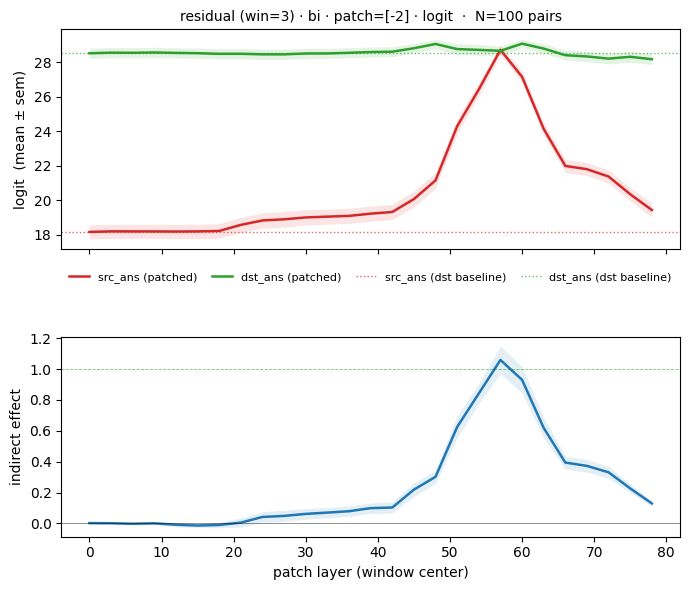

In [7]:
# ── viz · single config: src_ans / dst_ans scores (top) + IE (bottom) ────────
# Pick ONE configuration with the knobs below; only that figure is produced.
SHOW_METRIC = "logit"  # "logit" | "prob"
SHOW_DIRECTION = "bi"  # "ml->sl" | "sl->ml" | "bi" (pool both directions)
SHOW_PATCH_TOKENS = "[-2]"  # one of: "[-1]", "[-2]", "[-2, -1]"
SHOW_MODULE = "residual"  # one of MODULE_SPECS: residual | attn | mlp

# pool over the raw per-pair records so "bi" averages both directions' rows (not means-of-means)
sel_dirs = DIRECTIONS if SHOW_DIRECTION == "bi" else [SHOW_DIRECTION]
d = df[
    (df.metric == SHOW_METRIC)
    & (df.module == SHOW_MODULE)
    & (df.patch_tokens == SHOW_PATCH_TOKENS)
    & (df.direction.isin(sel_dirs))
]
assert not d.empty, "no rows for this config — check the knobs against what was swept"
s = (
    d.groupby("layer")
    .agg(
        src_mean=("patched", "mean"),     src_sem=("patched", _sem),
        dst_mean=("patched_dst", "mean"), dst_sem=("patched_dst", _sem),
        ie_mean=("ie", "mean"),           ie_sem=("ie", _sem),
        base_src=("base", "mean"),        base_dst=("base_dst", "mean"),
    )
    .reset_index()
    .sort_values("layer")
)

win = MODULE_SPECS[SHOW_MODULE][1]
fig, (ax_s, ax_ie) = plt.subplots(
    2, 1, sharex=True, figsize=(7.0, 6.0), gridspec_kw=dict(height_ratios=[1.1, 1.0])
)

# top — patched scores across window centers (src_ans red, dst_ans green) + unpatched baselines
ax_s.plot(s.layer, s.src_mean, "-", color="tab:red", lw=1.8, label="src_ans (patched)")
ax_s.fill_between(
    s.layer,
    s.src_mean - s.src_sem,
    s.src_mean + s.src_sem,
    color="tab:red",
    alpha=0.12,
    lw=0,
)
ax_s.plot(
    s.layer, s.dst_mean, "-", color="tab:green", lw=1.8, label="dst_ans (patched)"
)
ax_s.fill_between(
    s.layer,
    s.dst_mean - s.dst_sem,
    s.dst_mean + s.dst_sem,
    color="tab:green",
    alpha=0.12,
    lw=0,
)
ax_s.axhline(
    s.base_src.iloc[0],
    color="tab:red",
    ls=":",
    lw=1.0,
    alpha=0.7,
    label="src_ans (dst baseline)",
)
ax_s.axhline(
    s.base_dst.iloc[0],
    color="tab:green",
    ls=":",
    lw=1.0,
    alpha=0.7,
    label="dst_ans (dst baseline)",
)
ax_s.set_ylabel(f"{SHOW_METRIC}  (mean ± sem)")
ax_s.set_title(
    f"{SHOW_MODULE} (win={win}) · {SHOW_DIRECTION} · patch={SHOW_PATCH_TOKENS} · "
    f"{SHOW_METRIC}  ·  N={len(pairs)} pairs",
    fontsize=10,
)
# legend is drawn below this panel (single row, 4 cols) after layout — see end of cell

# bottom — indirect effect for the same config
ax_ie.plot(s.layer, s.ie_mean, "-", color="tab:blue", lw=1.8)
ax_ie.fill_between(
    s.layer,
    s.ie_mean - s.ie_sem,
    s.ie_mean + s.ie_sem,
    color="tab:blue",
    alpha=0.12,
    lw=0,
)
ax_ie.axhline(0, color="k", lw=0.6, alpha=0.5)
ax_ie.axhline(1, color="green", lw=0.6, ls="--", alpha=0.5)
ax_ie.set_ylabel("indirect effect")
ax_ie.set_xlabel("patch layer (window center)")

fig.tight_layout()
fig.subplots_adjust(hspace=0.42)  # open a gap between the panels to hold the legend
# legend below the top panel: single row, 4 columns, sitting above the IE plot
ax_s.legend(
    fontsize=8,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    frameon=False,
    columnspacing=1.3,
    handlelength=1.8,
)
plt.show()

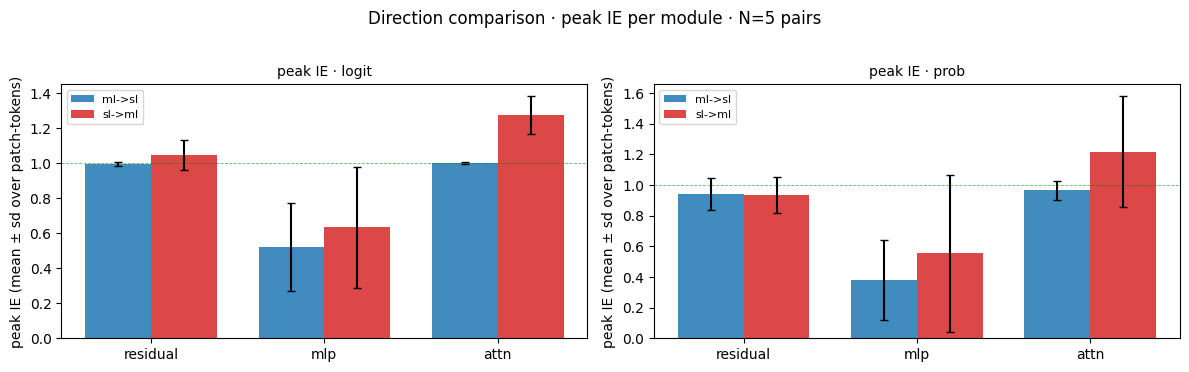


direction summary — mean peak IE over modules & patch-tokens:
direction    ml->sl    sl->ml
metric                       
logit      0.838968  0.985594
prob       0.761401  0.900495


In [6]:
# ── viz 2 · direction comparison: peak IE per module (mean ± sd over patch-tokens) ──
modules = list(MODULE_SPECS)
dir_colors = {"ml->sl": "tab:blue", "sl->ml": "tab:red"}
fig, axes = plt.subplots(1, len(METRICS), squeeze=False, figsize=(6.0 * len(METRICS), 3.6))
xpos, w = np.arange(len(modules)), 0.38
for c, metric in enumerate(METRICS):
    ax = axes[0][c]
    for di, direction in enumerate(DIRECTIONS):
        means, errs = [], []
        for mod in modules:
            vals = peak[(peak.metric == metric) & (peak.module == mod)
                        & (peak.direction == direction)]["peak_ie"]
            means.append(vals.mean())
            errs.append(vals.std(ddof=1) if len(vals) > 1 else 0.0)
        ax.bar(xpos + (di - 0.5) * w, means, w, yerr=errs, capsize=3,
               color=dir_colors[direction], label=direction, alpha=0.85)
    ax.set_xticks(xpos); ax.set_xticklabels(modules)
    ax.axhline(0, color="k", lw=0.6)
    ax.axhline(1, color="green", ls="--", lw=0.6, alpha=0.6)
    ax.set_title(f"peak IE · {metric}", fontsize=10)
    ax.set_ylabel("peak IE (mean ± sd over patch-tokens)")
    ax.legend(fontsize=8)
fig.suptitle(f"Direction comparison · peak IE per module · N={len(pairs)} pairs", y=1.02)
fig.tight_layout()
plt.show()

print("\ndirection summary — mean peak IE over modules & patch-tokens:")
print(peak.groupby(["metric", "direction"])["peak_ie"].mean().unstack().to_string())

# Gaze Heads

In [41]:
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-100 gaze heads  (compare_with='mean', q_span=15)  score range [2.725, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 85 more)


In [51]:
from src.tokens import prepare_input
from src.functional import generate_with_patch

source_example = build_example(
    rng=random.Random(12345),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="multiline",
)
source_prompt = replace_in_code_newline_with_tabnewline(source_example["full_prompt"]) + '   '
source_tokenized = prepare_input(source_prompt, tokenizer=mt)
source_gen = generate_with_patch(
    mt,
    inputs=source_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{source_prompt}[/white][plum1]{source_gen}[/plum1]")

destination_example = build_example(
    rng=random.Random(54321),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="singleline",
)
destination_prompt = replace_in_code_newline_with_tabnewline(destination_example["full_prompt"]) + '   '
destination_tokenized = prepare_input(destination_prompt, tokenizer=mt)
destination_gen = generate_with_patch(
    mt,
    inputs=destination_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{destination_prompt}[/white][sea_green3]{destination_gen}[/sea_green3]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's digits is divisible by 5
2. n is even
3. n has more than 2 ones in its binary representation

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = sum(int(d) for d in str(abs(n)))    
    a = a % 5 == 0    
    b = n % 2    
    b = b == 0    
    c = bin(n).count('1')    
    c = c > 2    
    print(f"Condition 

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. all of n's digits are even
2. n is divisible by 7
3. n is smaller than the number obtained by reversing its digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a =     
    a = all(d % 2 == 0 for d in a)    
    b = n % 7 == 0    
    c = n < int(str(n)[::-1])    
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 

In [53]:
from src.attention import get_attention_matrices, show_interactive_attention

value_weighted = True
# full_prompt = source_prompt + source_gen
full_prompt = destination_prompt + destination_gen

attn_info = get_attention_matrices(
    input = full_prompt,
    mt = mt,
    value_weighted = value_weighted,
)

# selected_heads = sorted(goalscope_heads)  # or gaze_heads
selected_heads = sorted(gaze_heads)  # or goalscope_heads
show_interactive_attention(
    attn_info=attn_info,
    selected_heads=selected_heads,
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"{len(selected_heads)} selected heads ({value_weighted=})",
    height=None,
)

'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>100 selected heads (value_weighted=True)</title>\n<style>\n #iaviz-17aa7d71 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-17aa7d71 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-17aa7d71 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-17aa7d71 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-17aa7d71 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-17aa7d71 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n   bord